In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
amazon_all = pd.read_csv(
    "../data/cleaned/amazon_master_2015_2025.csv",
    parse_dates=["order_date"]
)

print(amazon_all.shape)
print(amazon_all.head())

(1127609, 34)
      transaction_id order_date         customer_id   product_id  \
0  TXN_2015_00000001 2015-01-25  CUST_2015_00003884  PROD_000021   
1  TXN_2015_00000002 2015-01-05  CUST_2015_00011709  PROD_000055   
2  TXN_2015_00000003 2015-01-24  CUST_2015_00004782  PROD_000039   
3  TXN_2015_00000004 2015-01-28  CUST_2015_00008105  PROD_000085   
4  TXN_2015_00000005 2015-01-31  CUST_2015_00002955  PROD_000055   

                           product_name     category  subcategory     brand  \
0          Samsung Galaxy S6 16GB Black  Electronics  Smartphones   Samsung   
1          OnePlus OnePlus 2 16GB White  Electronics  Smartphones   OnePlus   
2      Samsung Galaxy Note 5 64GB Black  Electronics  Smartphones   Samsung   
3  Motorola Moto G (3rd Gen) 16GB Black  Electronics  Smartphones  Motorola   
4          OnePlus OnePlus 2 16GB White  Electronics  Smartphones   OnePlus   

   original_price_inr  discount_percent  ...  is_festival_sale  \
0           123614.29             27

In [3]:
# BUSINESS PERFORMANCE ANALYSIS

total_orders = amazon_all["transaction_id"].nunique()

total_revenue = amazon_all["final_amount_inr"].sum()

total_customers = amazon_all["customer_id"].nunique()

total_products = amazon_all["product_id"].nunique()

average_order_value = total_revenue / total_orders

total_quantity = amazon_all["quantity"].sum()

print("========== AMAZON BUSINESS OVERVIEW ==========")

print(f"Total Orders: {total_orders:,}")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")

========== AMAZON BUSINESS OVERVIEW ==========
Total Orders: 1,127,609
Total Revenue: ₹76,888,729,563.25
Total Customers: 354,969
Total Products: 2,004
Average Order Value: ₹68,187.40
Total Quantity Sold: 1,409,582


In [4]:
# YEAR-WISE REVENUE ANALYSIS

yearly_revenue = (
    amazon_all.groupby("order_year")["final_amount_inr"]
    .sum()
    .reset_index()
)

yearly_revenue.columns = ["Year", "Total_Revenue"]

print(yearly_revenue.to_string(index=False))

 Year  Total_Revenue
 2015   2.142163e+09
 2016   3.598316e+09
 2017   5.510026e+09
 2018   7.248545e+09
 2019   8.605901e+09
 2020   1.187319e+10
 2021   1.099021e+10
 2022   8.532312e+09
 2023   7.712999e+09
 2024   6.823413e+09
 2025   3.851650e+09


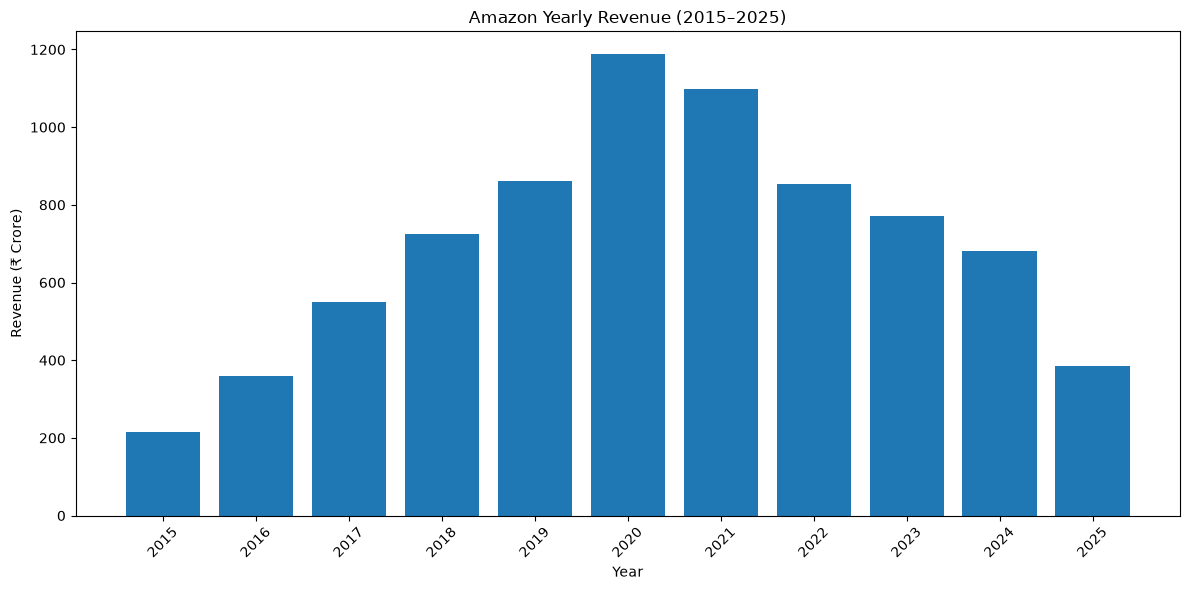

In [5]:
plt.figure(figsize=(12, 6))

plt.bar(
    yearly_revenue["Year"].astype(str),
    yearly_revenue["Total_Revenue"] / 10000000
)

plt.title("Amazon Yearly Revenue (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Revenue (₹ Crore)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

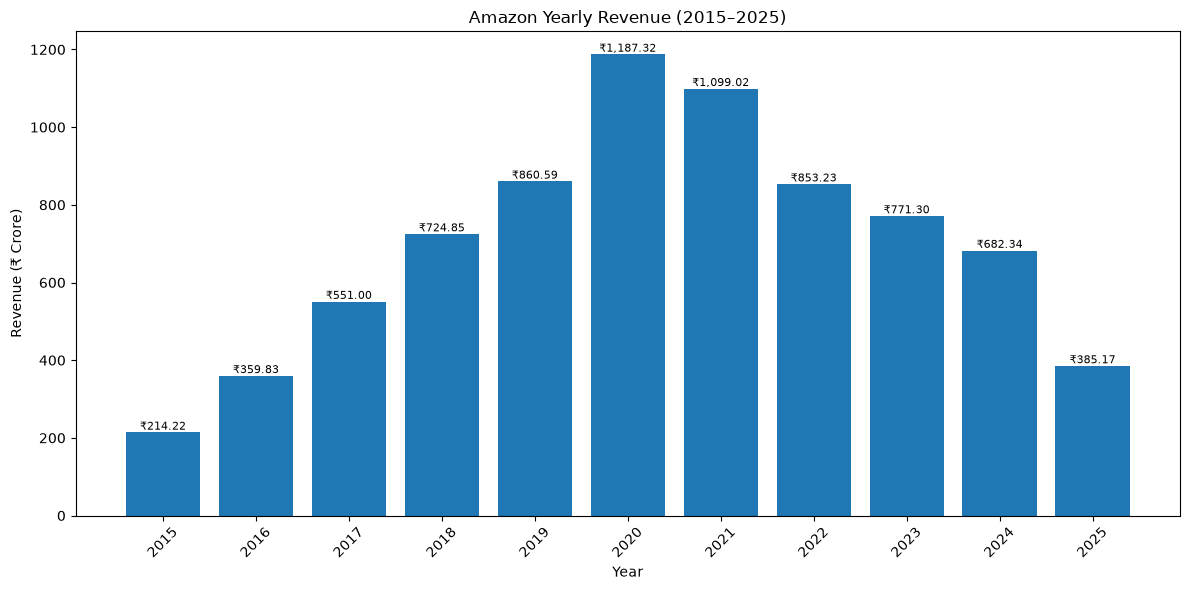

In [6]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    yearly_revenue["Year"].astype(str),
    yearly_revenue["Total_Revenue"] / 10000000
)

plt.title("Amazon Yearly Revenue (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Revenue (₹ Crore)")

# Display exact revenue value above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:,.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
# YEAR-OVER-YEAR REVENUE GROWTH

yearly_revenue["Revenue_Growth_Percentage"] = (
    yearly_revenue["Total_Revenue"].pct_change() * 100
)

print(yearly_revenue.to_string(index=False))

 Year  Total_Revenue  Revenue_Growth_Percentage
 2015   2.142163e+09                        NaN
 2016   3.598316e+09                  67.975780
 2017   5.510026e+09                  53.127907
 2018   7.248545e+09                  31.551925
 2019   8.605901e+09                  18.725908
 2020   1.187319e+10                  37.965735
 2021   1.099021e+10                  -7.436790
 2022   8.532312e+09                 -22.364427
 2023   7.712999e+09                  -9.602477
 2024   6.823413e+09                 -11.533590
 2025   3.851650e+09                 -43.552442


In [9]:
# CATEGORY-WISE REVENUE ANALYSIS

category_revenue = (
    amazon_all.groupby("category")["final_amount_inr"]
    .sum()
    .reset_index()
)

category_revenue.columns = ["Category", "Total_Revenue"]

category_revenue = category_revenue.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(category_revenue.to_string(index=False))

                 Category  Total_Revenue
              Electronics   7.687473e+10
Electronics & Accessories   1.400199e+07


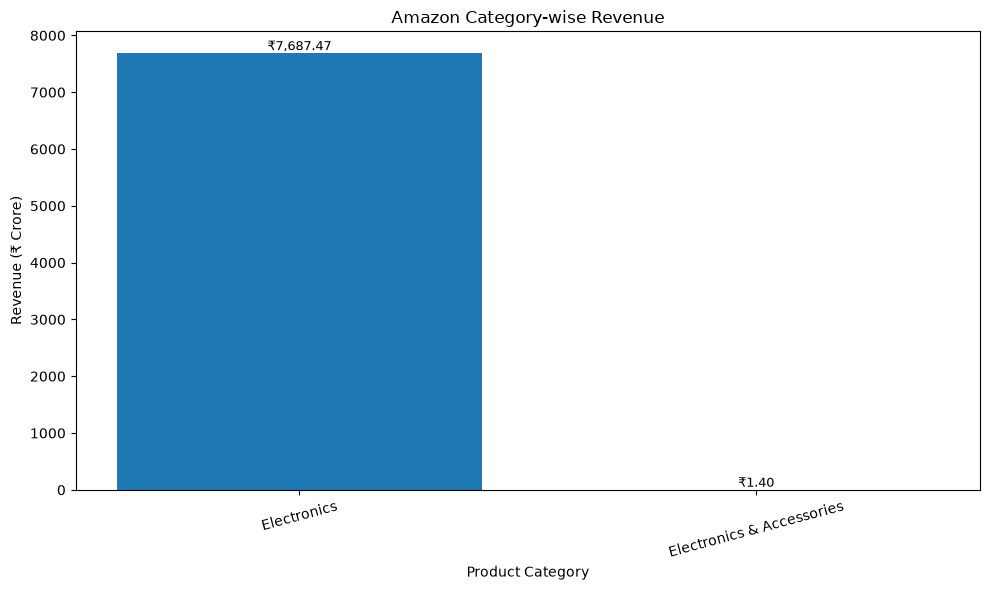

In [10]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    category_revenue["Category"],
    category_revenue["Total_Revenue"] / 10000000
)

plt.title("Amazon Category-wise Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue (₹ Crore)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:,.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [11]:
# CUSTOMER-WISE REVENUE ANALYSIS

customer_revenue = (
    amazon_all.groupby("customer_id")["final_amount_inr"]
    .sum()
    .reset_index()
)

customer_revenue.columns = ["Customer_ID", "Total_Revenue"]

customer_revenue = customer_revenue.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(customer_revenue.head(10).to_string(index=False))

       Customer_ID  Total_Revenue
CUST_2015_00003928     3757087.02
CUST_2016_00007974     3708826.25
CUST_2016_00001495     3533620.11
CUST_2018_00007329     3239479.72
CUST_2015_00009716     3134243.67
CUST_2020_00050279     3109580.24
CUST_2017_00014541     3102679.55
CUST_2015_00009173     3073245.76
CUST_2015_00002706     3026726.21
CUST_2015_00004117     3005482.80


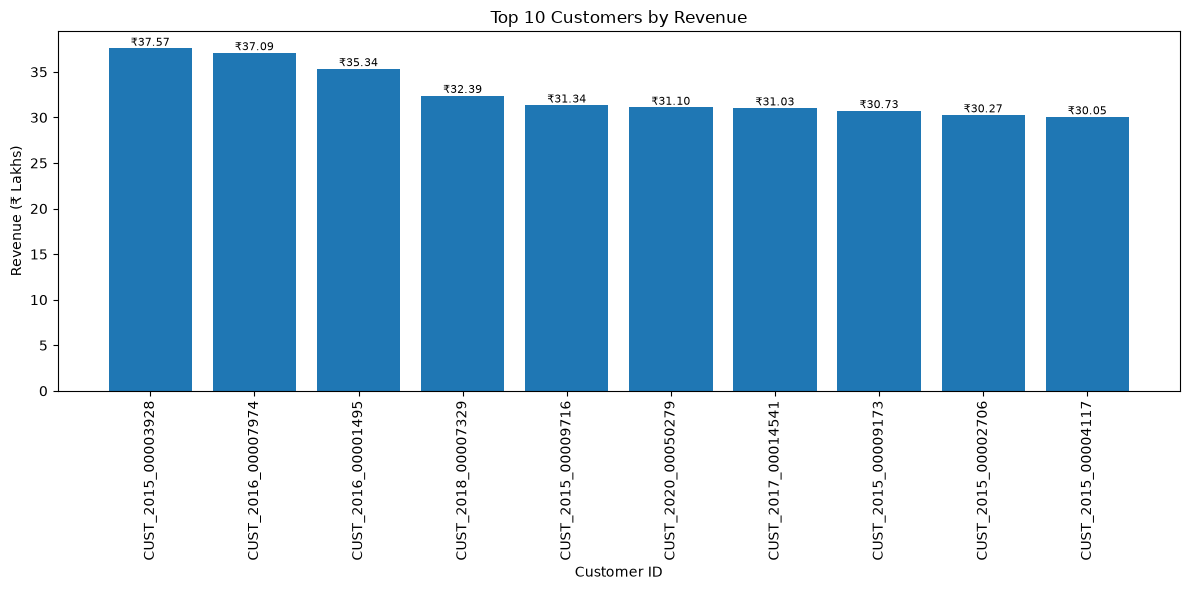

In [12]:
plt.figure(figsize=(12, 6))

top_10_customers = customer_revenue.head(10)

bars = plt.bar(
    top_10_customers["Customer_ID"],
    top_10_customers["Total_Revenue"] / 100000
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue (₹ Lakhs)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [13]:
state_revenue = (
    amazon_all.groupby("customer_state")["final_amount_inr"]
    .sum()
    .reset_index()
)

state_revenue.columns = ["State", "Total_Revenue"]

state_revenue = state_revenue.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(state_revenue.head(10).to_string(index=False))

         State  Total_Revenue
   Maharashtra   1.755014e+10
         Delhi   9.282344e+09
    Tamil Nadu   7.923753e+09
     Karnataka   7.680945e+09
       Gujarat   7.183017e+09
 Uttar Pradesh   6.793803e+09
   West Bengal   5.053097e+09
     Telangana   3.335962e+09
     Rajasthan   2.644470e+09
Madhya Pradesh   2.214093e+09


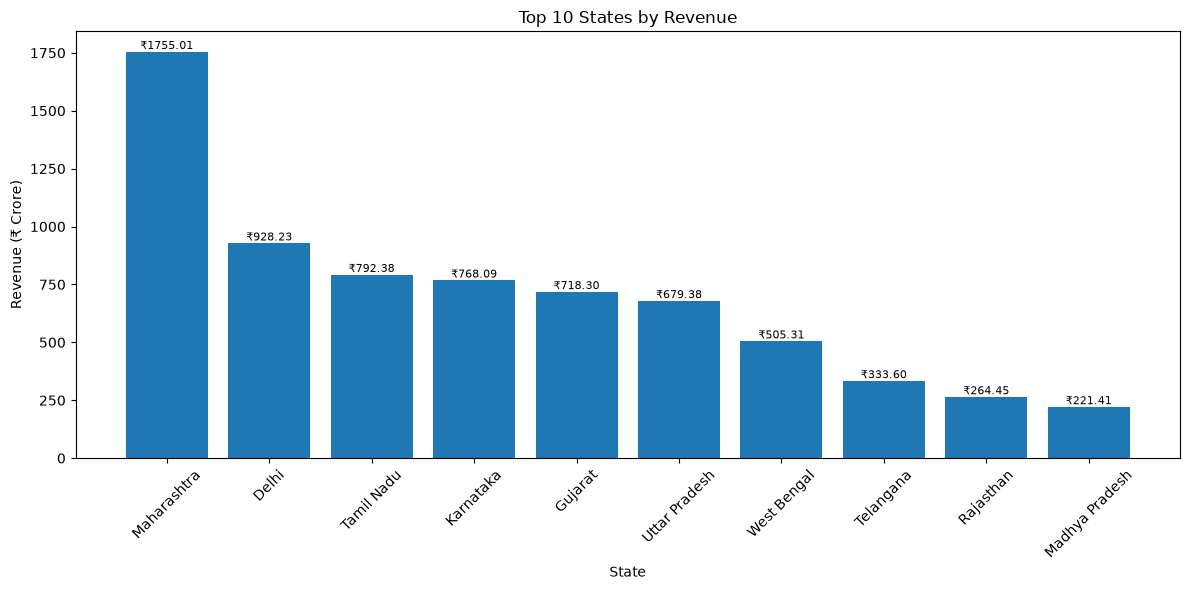

In [14]:
plt.figure(figsize=(12, 6))

top_10_states = state_revenue.head(10)

bars = plt.bar(
    top_10_states["State"],
    top_10_states["Total_Revenue"] / 10000000
)

plt.title("Top 10 States by Revenue")
plt.xlabel("State")
plt.ylabel("Revenue (₹ Crore)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
payment_analysis = (
    amazon_all.groupby("payment_method")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Total_Revenue=("final_amount_inr", "sum")
    )
    .reset_index()
)

payment_analysis = payment_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(payment_analysis.to_string(index=False))

payment_method  Total_Orders  Total_Revenue
           UPI        384228   2.517849e+10
           COD        322831   2.263827e+10
   Credit Card        172261   1.197304e+10
    Debit Card        140202   9.816262e+09
   Net Banking         64971   4.568869e+09
        Wallet         22821   1.565114e+09
          BNPL         20295   1.148682e+09


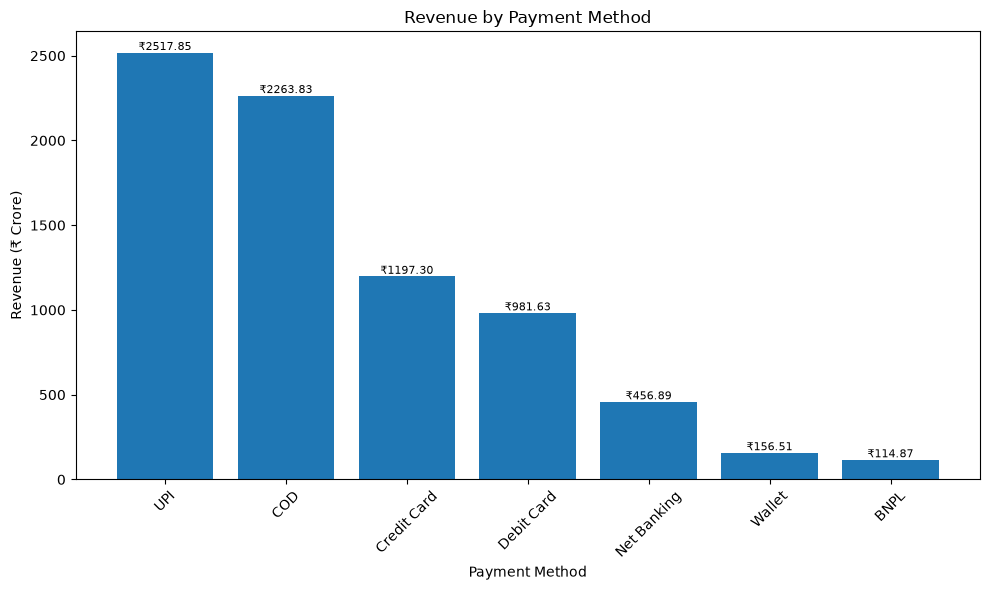

In [16]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    payment_analysis["payment_method"],
    payment_analysis["Total_Revenue"] / 10000000
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue (₹ Crore)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
return_analysis = (
    amazon_all.groupby("return_status")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Total_Revenue=("final_amount_inr", "sum")
    )
    .reset_index()
)

print(return_analysis.to_string(index=False))

return_status  Total_Orders  Total_Revenue
    Cancelled         26053   1.636262e+09
    Delivered       1022431   7.032930e+10
     Returned         79125   4.923170e+09


In [18]:
total_orders = return_analysis["Total_Orders"].sum()

return_analysis["Order_Percentage"] = (
    return_analysis["Total_Orders"] / total_orders
) * 100

print(return_analysis.to_string(index=False))

return_status  Total_Orders  Total_Revenue  Order_Percentage
    Cancelled         26053   1.636262e+09          2.310464
    Delivered       1022431   7.032930e+10         90.672476
     Returned         79125   4.923170e+09          7.017060


In [19]:
festival_analysis = (
    amazon_all.groupby("is_festival_sale")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Total_Revenue=("final_amount_inr", "sum")
    )
    .reset_index()
)

print(festival_analysis.to_string(index=False))

 is_festival_sale  Total_Orders  Total_Revenue
            False        777736   6.027034e+10
             True        349873   1.661839e+10


In [20]:
total_orders = festival_analysis["Total_Orders"].sum()
total_revenue = festival_analysis["Total_Revenue"].sum()

festival_analysis["Order_Percentage"] = (
    festival_analysis["Total_Orders"] / total_orders
) * 100

festival_analysis["Revenue_Percentage"] = (
    festival_analysis["Total_Revenue"] / total_revenue
) * 100

print(festival_analysis.to_string(index=False))

 is_festival_sale  Total_Orders  Total_Revenue  Order_Percentage  Revenue_Percentage
            False        777736   6.027034e+10         68.972135           78.386439
             True        349873   1.661839e+10         31.027865           21.613561


In [21]:
prime_analysis = (
    amazon_all.groupby("is_prime_member")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Total_Revenue=("final_amount_inr", "sum"),
        Unique_Customers=("customer_id", "nunique")
    )
    .reset_index()
)

print(prime_analysis.to_string(index=False))

is_prime_member  Total_Orders  Total_Revenue  Unique_Customers
              0         21078   1.305587e+09             19625
              1         12871   1.015507e+09             12262
          FALSE         21086   1.307972e+09             19644
          False        635593   3.942185e+10            190015
             No         20728   1.294507e+09             19333
           TRUE         12684   9.922969e+08             12095
           True        390675   3.054434e+10            155825
            Yes         12894   1.006668e+09             12299


In [22]:
amazon_all["is_prime_member"] = (
    amazon_all["is_prime_member"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "1": True,
        "yes": True,
        "false": False,
        "0": False,
        "no": False
    })
)

In [23]:
print(amazon_all["is_prime_member"].value_counts(dropna=False))

is_prime_member
False    698485
True     429124
Name: count, dtype: int64


In [24]:
prime_analysis = (
    amazon_all.groupby("is_prime_member")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Total_Revenue=("final_amount_inr", "sum"),
        Unique_Customers=("customer_id", "nunique")
    )
    .reset_index()
)

print(prime_analysis.to_string(index=False))

 is_prime_member  Total_Orders  Total_Revenue  Unique_Customers
           False        698485   4.332992e+10            194307
            True        429124   3.355881e+10            160662


In [25]:
prime_analysis["Revenue_Per_Customer"] = (
    prime_analysis["Total_Revenue"] /
    prime_analysis["Unique_Customers"]
)

prime_analysis["Average_Order_Value"] = (
    prime_analysis["Total_Revenue"] /
    prime_analysis["Total_Orders"]
)

print(prime_analysis.to_string(index=False))

 is_prime_member  Total_Orders  Total_Revenue  Unique_Customers  Revenue_Per_Customer  Average_Order_Value
           False        698485   4.332992e+10            194307         222997.215762         62034.145333
            True        429124   3.355881e+10            160662         208878.325679         78203.059163


In [26]:
monthly_revenue = (
    amazon_all.groupby("order_month")["final_amount_inr"]
    .sum()
    .reset_index()
)

monthly_revenue.columns = ["Month", "Total_Revenue"]

monthly_revenue = monthly_revenue.sort_values(
    by="Month"
)

print(monthly_revenue.to_string(index=False))

 Month  Total_Revenue
     1   6.261470e+09
     2   5.624702e+09
     3   5.231882e+09
     4   6.324784e+09
     5   5.831836e+09
     6   5.072544e+09
     7   5.710916e+09
     8   6.321906e+09
     9   6.164452e+09
    10   6.686355e+09
    11   7.688359e+09
    12   9.969525e+09


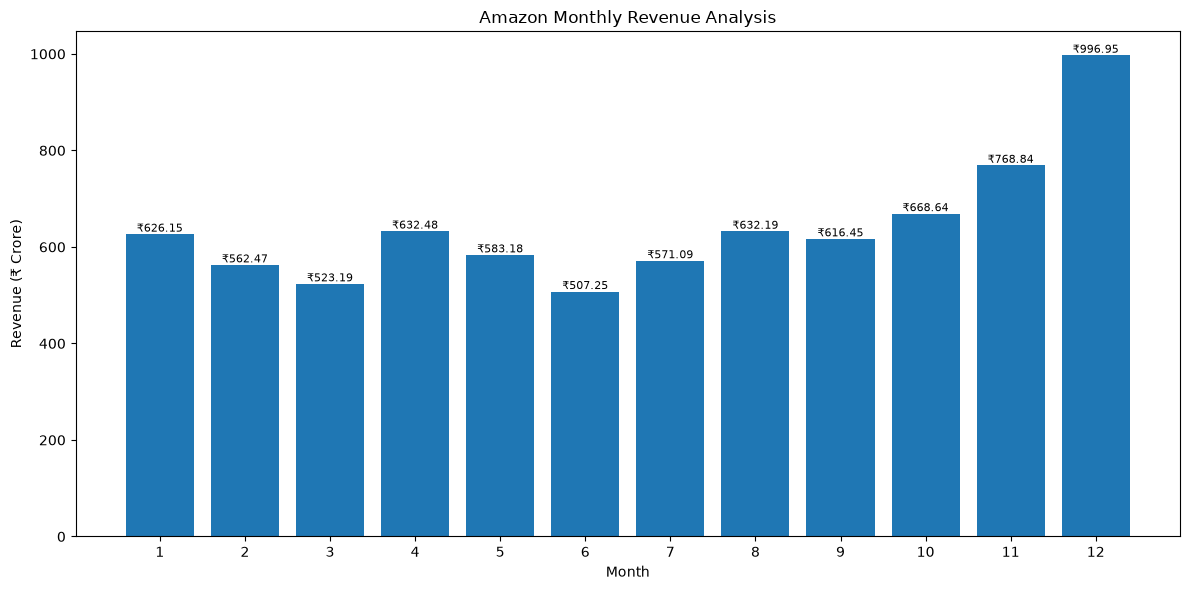

In [27]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    monthly_revenue["Month"].astype(str),
    monthly_revenue["Total_Revenue"] / 10000000
)

plt.title("Amazon Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue (₹ Crore)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [28]:
quarterly_revenue = (
    amazon_all.groupby("order_quarter")["final_amount_inr"]
    .sum()
    .reset_index()
)

quarterly_revenue.columns = ["Quarter", "Total_Revenue"]

quarterly_revenue = quarterly_revenue.sort_values(
    by="Quarter"
)

print(quarterly_revenue.to_string(index=False))

 Quarter  Total_Revenue
       1   1.711805e+10
       2   1.722916e+10
       3   1.819727e+10
       4   2.434424e+10


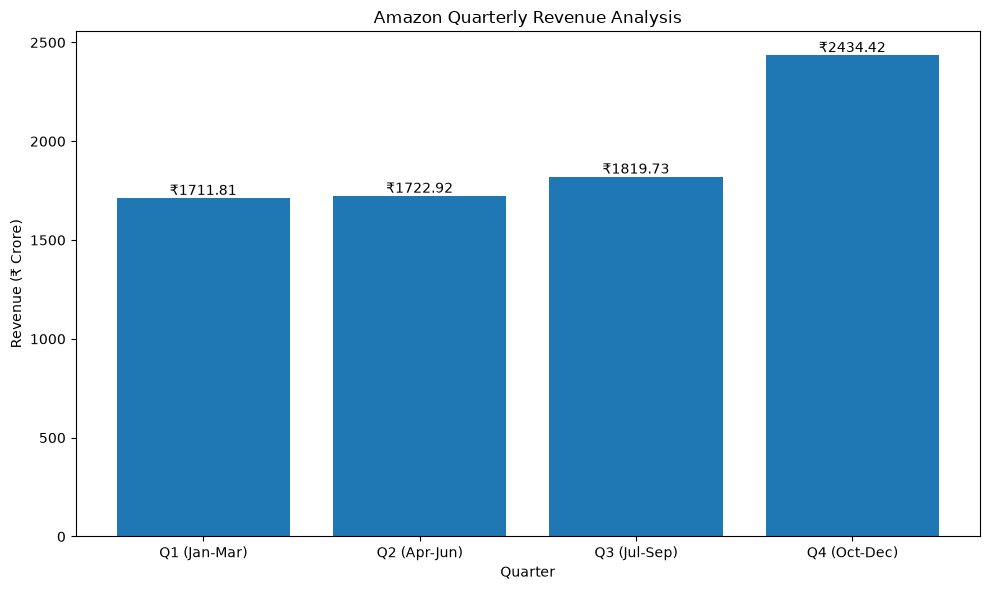

In [29]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    quarterly_revenue["Quarter"].astype(str),
    quarterly_revenue["Total_Revenue"] / 10000000
)

plt.title("Amazon Quarterly Revenue Analysis")
plt.xlabel("Quarter")
plt.ylabel("Revenue (₹ Crore)")

plt.xticks(
    range(4),
    ["Q1 (Jan-Mar)", "Q2 (Apr-Jun)", "Q3 (Jul-Sep)", "Q4 (Oct-Dec)"]
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [30]:
subcategory_revenue = (
    amazon_all.groupby("subcategory")["final_amount_inr"]
    .sum()
    .reset_index()
)

subcategory_revenue.columns = [
    "Subcategory",
    "Total_Revenue"
]

subcategory_revenue = subcategory_revenue.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(subcategory_revenue.head(10).to_string(index=False))

       Subcategory  Total_Revenue
       Smartphones   5.615210e+10
           Laptops   9.404032e+09
           Tablets   5.082893e+09
       Smart Watch   3.215059e+09
TV & Entertainment   1.923418e+09
             Audio   1.111227e+09


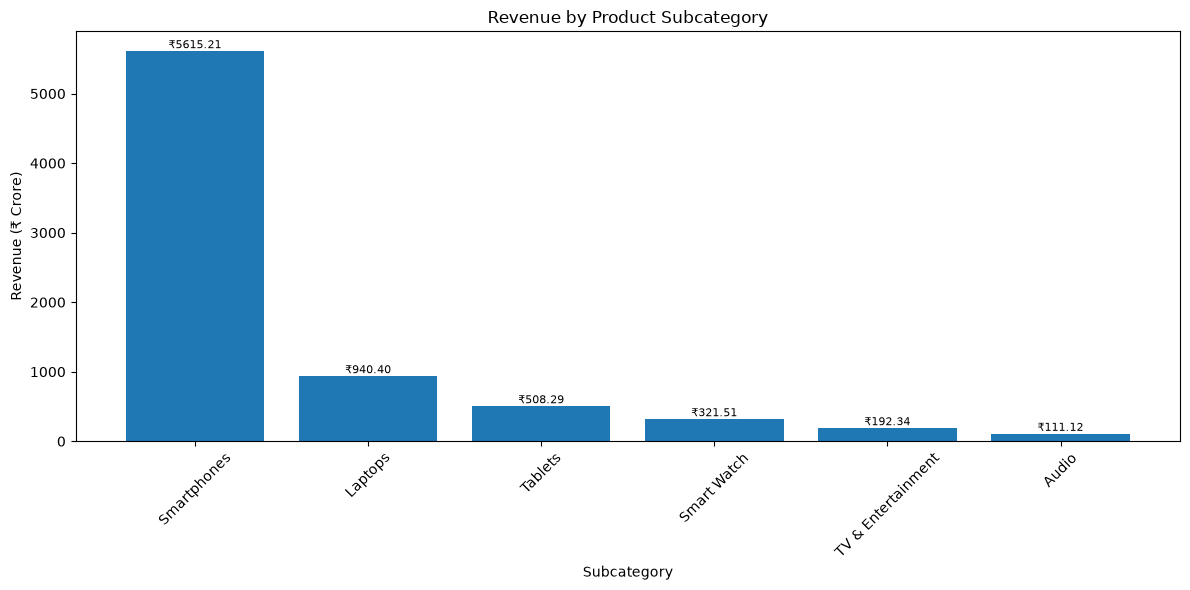

In [31]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    subcategory_revenue["Subcategory"],
    subcategory_revenue["Total_Revenue"] / 10000000
)

plt.title("Revenue by Product Subcategory")
plt.xlabel("Subcategory")
plt.ylabel("Revenue (₹ Crore)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"₹{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
product_revenue = (
    amazon_all.groupby("product_name")["final_amount_inr"]
    .sum()
    .reset_index()
)

product_revenue.columns = [
    "Product_Name",
    "Total_Revenue"
]

product_revenue = product_revenue.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(product_revenue.head(10).to_string(index=False))

                     Product_Name  Total_Revenue
     Samsung Galaxy S6 16GB Black   324321398.85
        Apple iPhone 6 64GB Black   303882383.93
Alienware Ultrabook 4GB RAM Black   279168145.65
      ASUS Inspiron 4GB RAM Black   253358158.81
        Apple iPhone 8 64GB Black   243777295.50
       Apple iPhone SE 32GB Black   243469885.07
     OnePlus OnePlus 2 32GB Black   241711820.20
        Apple iPhone 6 32GB White   241670888.79
Samsung Galaxy S6 Edge 16GB White   234171938.88
         Apple iPhone 8 16GB Blue   233816779.27


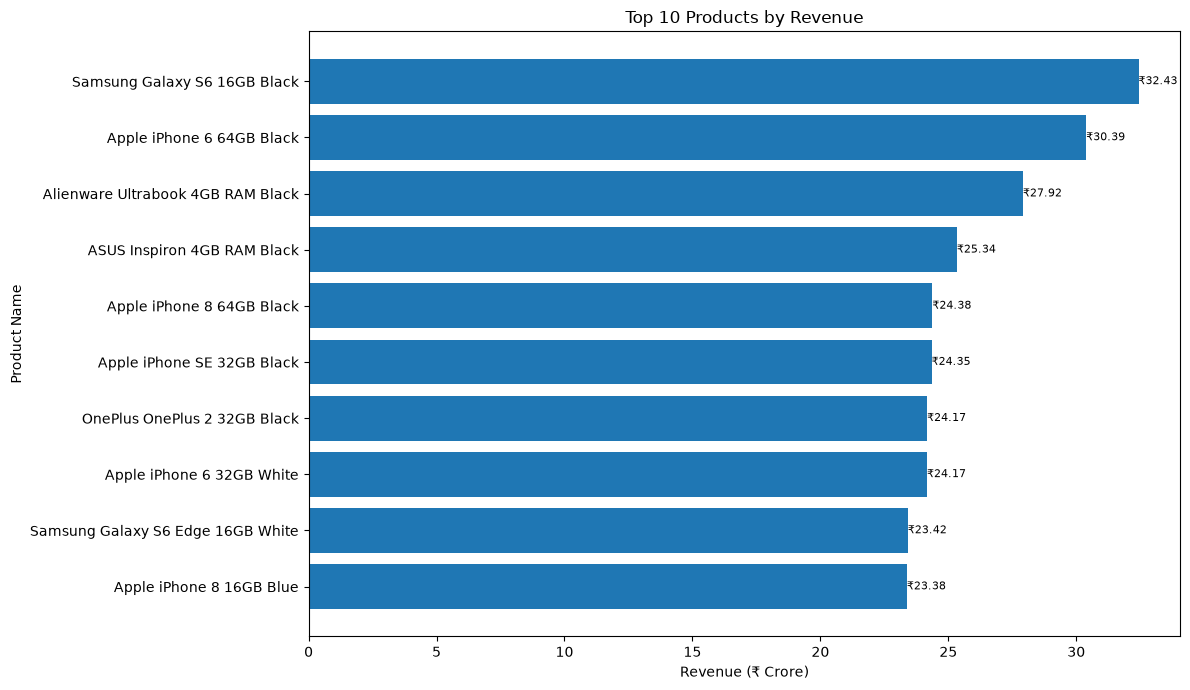

In [33]:
plt.figure(figsize=(12, 7))

top_10_products = product_revenue.head(10).sort_values(
    by="Total_Revenue"
)

bars = plt.barh(
    top_10_products["Product_Name"],
    top_10_products["Total_Revenue"] / 10000000
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (₹ Crore)")
plt.ylabel("Product Name")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"₹{width:.2f}",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [34]:
brand_revenue = (
    amazon_all.groupby("brand")["final_amount_inr"]
    .sum()
    .reset_index()
)

brand_revenue.columns = ["Brand", "Total_Revenue"]

brand_revenue = brand_revenue.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(brand_revenue.head(10).to_string(index=False))

    Brand  Total_Revenue
  Samsung   2.062142e+10
    Apple   1.632240e+10
  OnePlus   1.232417e+10
   Xiaomi   5.450159e+09
   Realme   3.015664e+09
     Vivo   2.348077e+09
     Oppo   2.268237e+09
   Lenovo   2.084388e+09
Alienware   1.659859e+09
     ASUS   1.458950e+09


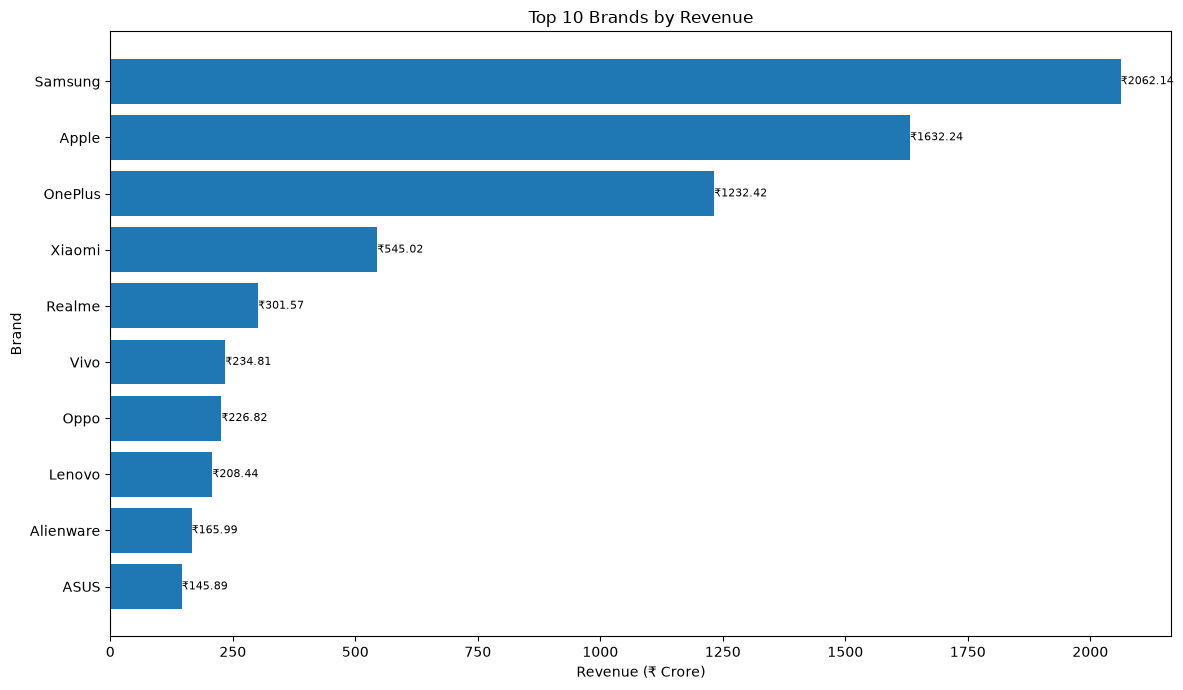

In [35]:
plt.figure(figsize=(12, 7))

top_10_brands = brand_revenue.head(10).sort_values(
    by="Total_Revenue"
)

bars = plt.barh(
    top_10_brands["Brand"],
    top_10_brands["Total_Revenue"] / 10000000
)

plt.title("Top 10 Brands by Revenue")
plt.xlabel("Revenue (₹ Crore)")
plt.ylabel("Brand")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"₹{width:.2f}",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [36]:
delivery_analysis = (
    amazon_all.groupby("delivery_type")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Average_Delivery_Days=("delivery_days", "mean"),
        Total_Revenue=("final_amount_inr", "sum")
    )
    .reset_index()
)

print(delivery_analysis.to_string(index=False))

TypeError: dtype 'str' does not support operation 'mean'

In [37]:
print(amazon_all["delivery_days"].dtype)

str


In [38]:
print(amazon_all["delivery_days"].unique()[:20])

<StringArray>
[       '6',        '4',        '3',        '5',        '7',  'Express',
        '0',       '-1', 'Same Day', '1-2 days',       '15',        '1',
        '2']
Length: 13, dtype: str


In [41]:
amazon_all["delivery_days"] = pd.to_numeric(
    amazon_all["delivery_days"],
    errors="coerce"
)

In [42]:
delivery_analysis = (
    amazon_all.groupby("delivery_type")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Average_Delivery_Days=("delivery_days", "mean"),
        Total_Revenue=("final_amount_inr", "sum")
    )
    .reset_index()
)

print(delivery_analysis.to_string(index=False))

delivery_type  Total_Orders  Average_Delivery_Days  Total_Revenue
      Express        128840               2.001168   1.003333e+10
     Same Day        214766               1.012862   1.685530e+10
     Standard        784003               4.184069   5.000010e+10


In [43]:
customer_tier_analysis = (
    amazon_all.groupby("customer_tier")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Total_Revenue=("final_amount_inr", "sum"),
        Unique_Customers=("customer_id", "nunique")
    )
    .reset_index()
)

customer_tier_analysis = customer_tier_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(customer_tier_analysis.to_string(index=False))

customer_tier  Total_Orders  Total_Revenue  Unique_Customers
        Metro        563829   4.242541e+10            168261
        Tier1        338631   2.218988e+10            110806
        Tier2        175157   9.949852e+09             58497
        Rural         49992   2.323583e+09             17405


In [44]:
age_group_analysis = (
    amazon_all.groupby("customer_age_group")
    .agg(
        Total_Orders=("transaction_id", "nunique"),
        Total_Revenue=("final_amount_inr", "sum"),
        Unique_Customers=("customer_id", "nunique")
    )
    .reset_index()
)

age_group_analysis = age_group_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(age_group_analysis.to_string(index=False))

customer_age_group  Total_Orders  Total_Revenue  Unique_Customers
             26-35        347899   2.379305e+10            120485
             18-25        316424   2.158446e+10            108986
             36-45        199100   1.354666e+10             68550
           Unknown        135315   9.204545e+09            108813
             46-55         99012   6.738818e+09             34089
               55+         29859   2.021196e+09             10416


In [45]:
customer_rating_analysis = (
    amazon_all.groupby("customer_rating")["transaction_id"]
    .nunique()
    .reset_index()
)

customer_rating_analysis.columns = [
    "Customer_Rating",
    "Total_Orders"
]

print(customer_rating_analysis.to_string(index=False))

 Customer_Rating  Total_Orders
             3.0         46903
             3.5         80157
             4.0        198296
             4.5        258705
             5.0        201852


In [46]:
product_rating_analysis = (
    amazon_all.groupby("product_rating")["transaction_id"]
    .nunique()
    .reset_index()
)

product_rating_analysis.columns = [
    "Product_Rating",
    "Total_Orders"
]

print(product_rating_analysis.to_string(index=False))

 Product_Rating  Total_Orders
            3.0          6700
            3.1          7832
            3.2         40194
            3.3         68674
            3.4         56497
            3.5         63162
            3.6         73098
            3.7         66430
            3.8         79047
            3.9         67886
            4.0         87698
            4.1         76381
            4.2         79082
            4.3         70662
            4.4         59987
            4.5         81814
            4.6         74904
            4.7         52385
            4.8         15176
